<center><h1>Tang_Xiaoyun_HW3</h1></center>
<br>
<br>

Name: Xiaoyun Tang
<br>
Github Username: Nokiovo099
<br>
USC ID: 3843547131

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

Get the AReM Data Set

I downloaded the AReM data and put it in the data/AReM folder. There are 7 folders (7 activities) and 88 files.
Each file has a time column and 6 time series.

Some files need a little cleaning:
- Lines that start with # are notes, so I skip them.
- One file (bending2/dataset4.csv) uses spaces instead of commas, and two files (cycling/dataset9.csv, cycling/dataset14.csv) have an extra comma at the end of a line. To fix both problems, I change every comma into a space and then split the line by spaces.
- sitting/dataset8.csv has 479 rows instead of 480 (one row is missing). I keep the 479 rows that are there and do not fill in the missing value. Most features (like the mean and median) will barely change. But if the missing value was the smallest or largest value, min or max of this file could be a little different.

In [2]:
# find the data folder with a relative path
# (works if the notebook is run from the notebook/ folder or from the repo folder)
if os.path.exists("../data/AReM"):
    data_dir = "../data/AReM"
else:
    data_dir = "data/AReM"
print("Data folder:", data_dir)

column_names = ["time", "avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]


def load_file(file_path):
    rows = []
    with open(file_path) as f:
        for line in f:
            line = line.strip()
            # skip empty lines and the header lines that start with #
            if line == "" or line.startswith("#"):
                continue
            # some files use spaces and some have an extra comma at the end,
            # so just turn commas into spaces and split
            line = line.replace(",", " ")
            rows.append([float(x) for x in line.split()])
    return pd.DataFrame(rows, columns=column_names)


activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]

total = 0
for activity in activities:
    files = [f for f in os.listdir(os.path.join(data_dir, activity)) if f.endswith(".csv")]
    print(activity, ":", len(files), "files")
    total += len(files)
print("Total:", total, "files")

Data folder: data/AReM


FileNotFoundError: [Errno 2] No such file or directory: 'data/AReM/bending1'

**Result:** There are 7 activity folders and 88 files in total. This matches the dataset description, which says there are 88 instances. The two bending folders have fewer files (7 and 6) than the other five activities (15 each).

In [ ]:
example = load_file(os.path.join(data_dir, "walking", "dataset1.csv"))
print("walking/dataset1.csv shape:", example.shape)

missing_row_file = load_file(os.path.join(data_dir, "sitting", "dataset8.csv"))
print("sitting/dataset8.csv shape:", missing_row_file.shape)

example.head()

walking/dataset1.csv shape: (480, 7)
sitting/dataset8.csv shape: (479, 7)


,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0.0,35.00,3.67,16.50,3.77,14.00,1.63
1,250.0,28.50,3.35,17.50,3.77,12.25,3.90
2,500.0,35.50,2.87,15.75,2.86,17.75,5.07
3,750.0,29.75,12.19,16.25,2.17,20.75,2.59
4,1000.0,27.00,2.12,16.75,0.83,24.75,1.64


**Result:** A normal file has **480 rows and 7 columns**. Each row is one time point (every 250 ms for 120 seconds, so 120 / 0.25 = 480 rows). The 7 columns are time plus the 6 time series. As I said above, sitting/dataset8.csv has 479 rows because one time point is missing in the original file.

### (b) Test and Train Data

- In bending1 and bending2: datasets 1 and 2 are **test** data.
- In the other folders: datasets 1, 2 and 3 are **test** data.
- Everything else is **train** data.

In [ ]:
split_rows = []
for activity in activities:
    files = [f for f in os.listdir(os.path.join(data_dir, activity)) if f.endswith(".csv")]
    for f in files:
        number = int(f.replace("dataset", "").replace(".csv", ""))
        # bending folders: dataset 1-2 are test, other folders: dataset 1-3
        if activity == "bending1" or activity == "bending2":
            test_limit = 2
        else:
            test_limit = 3
        if number <= test_limit:
            split = "test"
        else:
            split = "train"
        split_rows.append([activity, number, f, split])

split_table = pd.DataFrame(split_rows, columns=["activity", "number", "dataset", "split"])
split_table = split_table.sort_values(["activity", "number"]).reset_index(drop=True)

print("Number of train instances:", (split_table["split"] == "train").sum())
print("Number of test instances:", (split_table["split"] == "test").sum())
split_table[split_table["split"] == "test"]

Number of train instances: 69
Number of test instances: 19


,activity,number,dataset,split
0,bending1,1,dataset1.csv,test
1,bending1,2,dataset2.csv,test
7,bending2,1,dataset1.csv,test
8,bending2,2,dataset2.csv,test
13,cycling,1,dataset1.csv,test
14,cycling,2,dataset2.csv,test
15,cycling,3,dataset3.csv,test
28,lying,1,dataset1.csv,test
29,lying,2,dataset2.csv,test
30,lying,3,dataset3.csv,test


**Result:** The training set has **69 instances** and the test set has **19 instances** (2 + 2 from the two bending folders, plus 3 × 5 = 15 from the other five folders). 69 + 19 = 88, so every file is used exactly once. The table above lists all 19 test files.

### (c) Feature Extraction

#### i. Research

Time-domain features are numbers we calculate directly from the values of a time series $x_1, x_2, \dots, x_n$. Common ones are:

- **Minimum** and **maximum**: the smallest and largest values.
- **Mean**: the average value.
- **Median**: the middle value.
- **Standard deviation** and **variance**: how spread out the values are.
- **First quartile** and **third quartile**: the 25% and 75% points of the data.
- **Range**: max − min.
- **Interquartile range**: third quartile − first quartile.
- **Skewness**: whether the values lean to one side.
- **Kurtosis**: whether there are many extreme values.
- **Energy**: the sum of the squared values, $\sum_{t=1}^{n} x_t^2$. It gets bigger when the signal is bigger or longer.
- **Root mean square (RMS)**: $\sqrt{\frac{1}{n}\sum_{t=1}^{n} x_t^2}$. It shows how big the signal is on average. Energy and RMS are related, but they are not the same number.
- **Number of peaks**: how many times the signal goes up and comes back down.
- **Autocorrelation**: how similar the signal is to itself a few steps later (does it repeat a pattern?).

#### ii. Extraction

For each of the 88 instances, I calculate 7 features (min, max, mean, median, standard deviation, 1st quartile, 3rd quartile) for each of the 6 time series. So each instance has 7 × 6 = 42 features. I use the features directly, with no normalization.

Note: pandas .std() gives the sample standard deviation (it divides by n − 1, which is ddof=1).

In [ ]:
feature_rows = []

for i in range(len(split_table)):
    activity = split_table.loc[i, "activity"]
    file_name = split_table.loc[i, "dataset"]
    df = load_file(os.path.join(data_dir, activity, file_name))

    row = {}
    for k in range(1, 7):     # 6 time series
        series = df[column_names[k]]
        row["min" + str(k)] = series.min()
        row["max" + str(k)] = series.max()
        row["mean" + str(k)] = series.mean()
        row["median" + str(k)] = series.median()
        row["std" + str(k)] = series.std()
        row["1st_quart" + str(k)] = series.quantile(0.25)
        row["3rd_quart" + str(k)] = series.quantile(0.75)
    feature_rows.append(row)

features = pd.DataFrame(feature_rows)
features.index = range(1, 89)     # instance number starts from 1
features.index.name = "Instance"

print(features.shape)
features.round(3)

(88, 42)


,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


**Result:** The new dataset has **88 rows (one for each instance) and 42 feature columns** (7 features × 6 time series), with the same column names as the homework (min1, max1, ..., 1st_quart6, 3rd_quart6). Instances 1–7 are bending1, 8–13 are bending2, 14–28 are cycling, 29–43 are lying, 44–58 are sitting, 59–73 are standing and 74–88 are walking.

We can already see some differences between activities. For example, the walking instances (84–88) have mean2 around 4.4, but the bending1 instances (1–5) have mean2 only around 0.36–0.70. This makes sense: var_rss12 measures how much the signal changes, and walking moves a lot more than bending.

**Duplicate files:** When I looked at the table, I found some rows with the same feature values. I then compared the raw files and found:
- These pairs of files are **exact copies**: cycling dataset1 and dataset15 (instances 14 and 28), lying dataset1 and dataset15 (29 and 43), lying 3 and 11 (31 and 39), lying 5 and 12 (33 and 40), lying 7 and 13 (35 and 41), lying 9 and 14 (37 and 42).
- lying dataset10 (instance 38) is **almost a copy** of lying dataset1: only 1 of the 480 rows is different.

So some files in the original AReM data are copies of each other. The homework asks us to use all 88 instances, so I keep all of them. But this matters later:
- Some **test** files (cycling dataset1, lying dataset1, lying dataset3) have an exact copy in the **training** set. In Homework 4, the test accuracy for these classes may look better than it really is.
- In the bootstrap below, the 88 rows are not all different, so we have a bit less information than 88 truly different instances.

I also keep the activity name and the train/test label in the table, because Homework 4 will need them.

In [ ]:
features["activity"] = split_table["activity"].values
features["split"] = split_table["split"].values
feature_names = features.columns[:42]     # first 42 columns are the features

#### iii. Standard Deviation

First I calculate the standard deviation of each feature. Then I use the bootstrap to build a 90% confidence interval:

1. Randomly pick 88 rows from the 88 instances with replacement. This is one bootstrap sample.
2. Calculate the standard deviation of each feature in this sample.
3. Do this B = 1000 times.
4. For each feature, the 5th percentile and the 95th percentile of the 1000 values give the 90% confidence interval.

In [ ]:
X = features[feature_names]
B = 1000

boot_stds = []
for b in range(B):
    # pick 88 rows with replacement
    sample = X.sample(n=88, replace=True, random_state=b)
    boot_stds.append(sample.std())
boot_stds = pd.DataFrame(boot_stds)

std_table = pd.DataFrame({
    "std": X.std(),
    # 90% CI -> 5th and 95th percentile
    "CI lower (5%)": boot_stds.quantile(0.05),
    "CI upper (95%)": boot_stds.quantile(0.95),
})
std_table.round(3)

,std,CI lower (5%),CI upper (95%)
min1,9.570,8.287,10.754
max1,4.394,3.330,5.308
mean1,5.336,4.713,5.879
median1,5.440,4.801,5.996
std1,1.772,1.565,1.950
1st_quart1,6.154,5.570,6.671
3rd_quart1,5.139,4.310,5.838
min2,0.000,0.000,0.000
max2,5.063,4.626,5.388
mean2,1.574,1.398,1.715


**Result:** The table gives the estimated standard deviation and the 90% bootstrap confidence interval for all 42 features. Some things I noticed:
- In my results, every estimated standard deviation is inside its confidence interval. (This is not guaranteed by the percentile bootstrap, but it happened here.)
- min1 has the biggest standard deviation (about 9.57, with CI about [8.29, 10.75]). The minimum of time series 1 changes a lot between instances (for example, walking goes much lower than sitting).
- min2 and min4 have standard deviation **0** and CI **[0, 0]**. Their minimum is 0 in every instance, so every bootstrap sample also gives 0. These two features are the same for all activities, so they cannot help us classify.
- min6 is also almost always 0, so its standard deviation is very small (about 0.046).

To see the results more easily, I draw one small bar chart for each time series. Each bar is the estimated standard deviation of a feature, and the black line on top of the bar shows its 90% bootstrap confidence interval.

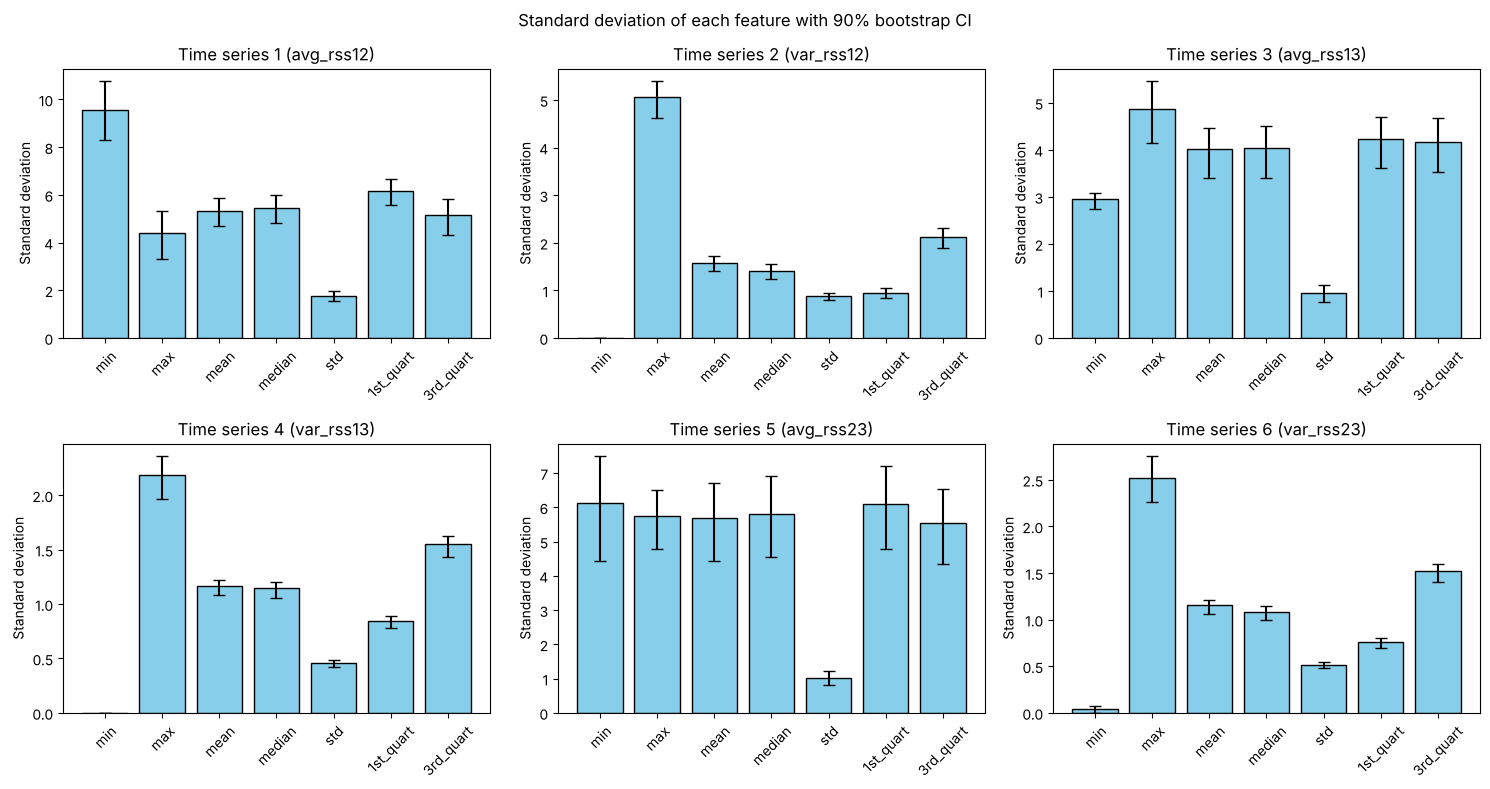

In [ ]:
stat_names = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for k in range(1, 7):
    ax = axes[(k - 1) // 3, (k - 1) % 3]
    rows = [name + str(k) for name in stat_names]
    est = std_table.loc[rows, "std"]
    lower = std_table.loc[rows, "CI lower (5%)"]
    upper = std_table.loc[rows, "CI upper (95%)"]
    error = [est - lower, upper - est]     # yerr wants the distance from the bar top
    ax.bar(stat_names, est, yerr=error, capsize=4, color="skyblue", edgecolor="black")
    ax.set_title("Time series " + str(k) + " (" + column_names[k] + ")")
    ax.set_ylabel("Standard deviation")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Standard deviation of each feature with 90% bootstrap CI")
plt.tight_layout()
plt.show()

From the charts we can see that the features of time series 1, 3 and 5 (the average signals) have much bigger standard deviations than the features of time series 2, 4 and 6 (the variance signals). So the average signals change more from one instance to another. The single biggest standard deviation is min1.

Time series 5 has the widest confidence intervals. A wide interval does not mean the feature changes more between instances. It means we are **less sure** about the value of the standard deviation (the bootstrap estimates move around more).

#### iv. Select Features

**I choose min, mean, and max** as the three most important features.

- **Mean** shows the normal level of the signal, and it can be different for different activities.
- **Min** and **max** show the lowest and highest values the signal reaches. Moving activities (like walking) can go much lower than still activities (like sitting).
- Median and quartiles also describe the middle part of the data, so I think they will often give similar information to the mean. Min and max add something different: the edges of the data.
- I did not pick the standard deviation this time. It is not the same thing as the var_rss time series (std1 is computed from the whole avg_rss12 series, while var_rss12 is measured inside each small time window), so it could still be useful. I just chose the three features that I think are easiest to understand and compare.

This is my first choice based on what the features mean. It is not proven to be the best choice yet; we can only check that with classifiers in Homework 4.

To check my choice, the table below shows the average min, mean and max of time series 1 for each activity. I only use the **training** instances here, so the test set stays separate for Homework 4.

In [ ]:
train = features[features["split"] == "train"]     # only use training data to choose features
train.groupby("activity")[["min1", "mean1", "max1"]].mean().round(2)

,min1,mean1,max1
activity,,,
bending1,34.85,43.05,47.38
bending2,23.12,31.12,44.00
cycling,24.22,36.62,44.40
lying,33.50,39.82,42.87
sitting,34.87,41.06,45.82
standing,34.96,43.97,47.13
walking,19.62,34.51,46.56


**Result (training instances only):** The three features look different between activities:
- **min1**: walking (19.62) and bending2 (23.12) go much lower than sitting (34.87) or bending1 (34.85).
- **mean1**: bending2 has the lowest mean (31.12) and standing has the highest (43.97).
- **max1**: lying has the lowest max (42.87), while the others are around 44–47.

Because each feature separates different groups of activities, using all three together should help the classifiers in Homework 4.

## 2. ISLR 3.7.4

RSS (residual sum of squares) $= \sum_{i=1}^{n}(y_i - \hat{y}_i)^2$, the total squared error of the model. We have 100 observations. We fit a linear regression and a cubic regression ($Y = \beta_0 + \beta_1X + \beta_2X^2 + \beta_3X^3 + \epsilon$).

### (a) Linear Train

**Q:** Suppose that the true relationship between X and Y is linear, i.e. $Y = \beta_0 + \beta_1X + \epsilon$. Consider the training residual sum of squares (RSS) for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.

**A:** **The cubic regression has lower (or equal) training RSS.**

The cubic model is more flexible. If $\beta_2 = \beta_3 = 0$, it is the same as the linear model, so its training RSS can never be bigger. The extra terms also fit some of the random noise in the training data, so the training RSS usually gets a little smaller.

### (b) Linear Test

**Q:** Answer (a) using test rather than training RSS.

**A:** **We would expect the linear regression to have lower test RSS.**

The true relationship is linear, so the linear model is already correct. The cubic model's extra terms only fit the noise in the training data (overfitting). This noise is different in the test data, so the cubic model usually makes bigger errors on the test data. This is what we expect on average; for one particular test set, the cubic model could still be a little better just by chance.

### (c) Not Linear Train

**Q:** Suppose that the true relationship between X and Y is not linear, but we don't know how far it is from linear. Consider the training RSS for the linear regression, and also the training RSS for the cubic regression. Would we expect one to be lower than the other, would we expect them to be the same, or is there not enough information to tell? Justify your answer.

**A:** **The cubic regression has lower (or equal) training RSS.**

The reason is the same as in (a): the more flexible model always fits the training data at least as well. This is true whether the real relationship is linear or not.

### (d) Not Linear Testing

**Q:** Answer (c) using test rather than training RSS.

**A:** **There is not enough information to tell.**

- If the real relationship is far from linear, and a cubic curve can describe it well, the cubic model can follow the curve better, so it would likely have lower test RSS.
- If the real relationship is only a little bit non-linear, the linear model might still do better, because the cubic model may overfit.

Since we don't know how non-linear the relationship is, we cannot decide.

## 3(a). Extra Practice: ISLR 3.7.3

Model: $\hat{Y} = 50 + 20\,GPA + 0.07\,IQ + 35\,Level + 0.01\,GPA \times IQ - 10\,GPA \times Level$ (Level = 1 for female, 0 for male; salary in thousands of dollars).

**(a)** Female − Male $= 35 - 10 \times GPA$. This is negative when GPA > 3.5, so males earn more when GPA is high enough. **Answer: (iii).**

**(b)** $\hat{Y} = 50 + 20(4.0) + 0.07(110) + 35 + 0.01(4.0)(110) - 10(4.0) = 137.1$, so the predicted salary is **$137,100**.

**(c)** **False.** A small coefficient does not mean there is no interaction effect. GPA × IQ is a big number (about 400), so the coefficient looks small because of the units. To check the evidence, we need to look at the p-value of the coefficient.

## 3(b). Extra Practice: ISLR 3.7.5

Without an intercept, $\hat{\beta} = \dfrac{\sum_{i'=1}^{n} x_{i'}y_{i'}}{\sum_{j=1}^{n} x_j^2}$, so

$$\hat{y}_i = x_i\hat{\beta} = \sum_{i'=1}^{n}\frac{x_i x_{i'}}{\sum_{j=1}^{n} x_j^2}\, y_{i'}$$

Therefore $a_{i'} = \dfrac{x_i x_{i'}}{\sum_{j=1}^{n} x_j^2}$.